# 03 · Results, ablations, and figures
The primary comparison uses two-second annotation errors. Confidence intervals resample held-out participants after averaging the three seeds for each participant. The analysis keeps source-only, uncorrected, and full-vector baselines visible alongside the component ablations.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "har").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"

from har.experiments import SEEDS, run as run_experiments
from har.report import participant_scores, quality_summary

if os.environ.get("HAR_RERUN_DATA") == "1":
    run_experiments()
scores = pd.read_csv(RESULTS / "scores.csv")
assert sorted(scores.seed.unique()) == sorted(SEEDS)
assert set(scores.dataset) == {"HAPT", "MotionSense"}
full = scores[scores["mode"] == "full_vectors"]
assert (full.prediction_agreement == 1).all()
paired = quality_summary(participant_scores(scores))
display(pd.read_csv(RESULTS / "tables" / "quality_primary.csv"))

,Dataset,Method,Macro-F1 % [95% CI],Δ vs wrong labels (pp)
0,HAPT,Source only,"81.05 [77.79, 84.00]","+3.13 [-0.04, 6.23]"
1,HAPT,Keep wrong labels,"77.92 [75.16, 80.56]","+0.00 [0.00, 0.00]"
2,HAPT,Add corrected labels only,"79.22 [76.53, 81.74]","+1.29 [0.34, 2.28]"
3,HAPT,Remove source prior,"78.10 [74.37, 81.51]","+0.18 [-2.42, 2.88]"
4,HAPT,8-block edit history,"78.61 [76.01, 81.13]","+0.68 [-0.19, 1.57]"
5,HAPT,2-second edit grid,"79.69 [76.91, 82.29]","+1.76 [-0.11, 3.90]"
6,HAPT,Full-vector reference,"80.15 [77.30, 82.96]","+2.22 [-0.31, 4.78]"
7,HAPT,Unpacked summaries,"80.15 [77.30, 82.96]","+2.22 [-0.31, 4.78]"
8,HAPT,Packed journal,"80.15 [77.30, 82.96]","+2.22 [-0.31, 4.78]"
9,MotionSense,Source only,"77.18 [69.19, 84.20]","-6.68 [-13.95, -0.12]"


## Primary comparisons and sensitivity
The shaded band shows the participant-bootstrap interval around the proposed method. The two-second setting is the primary comparison. One- and three-second errors are sensitivity analyses.

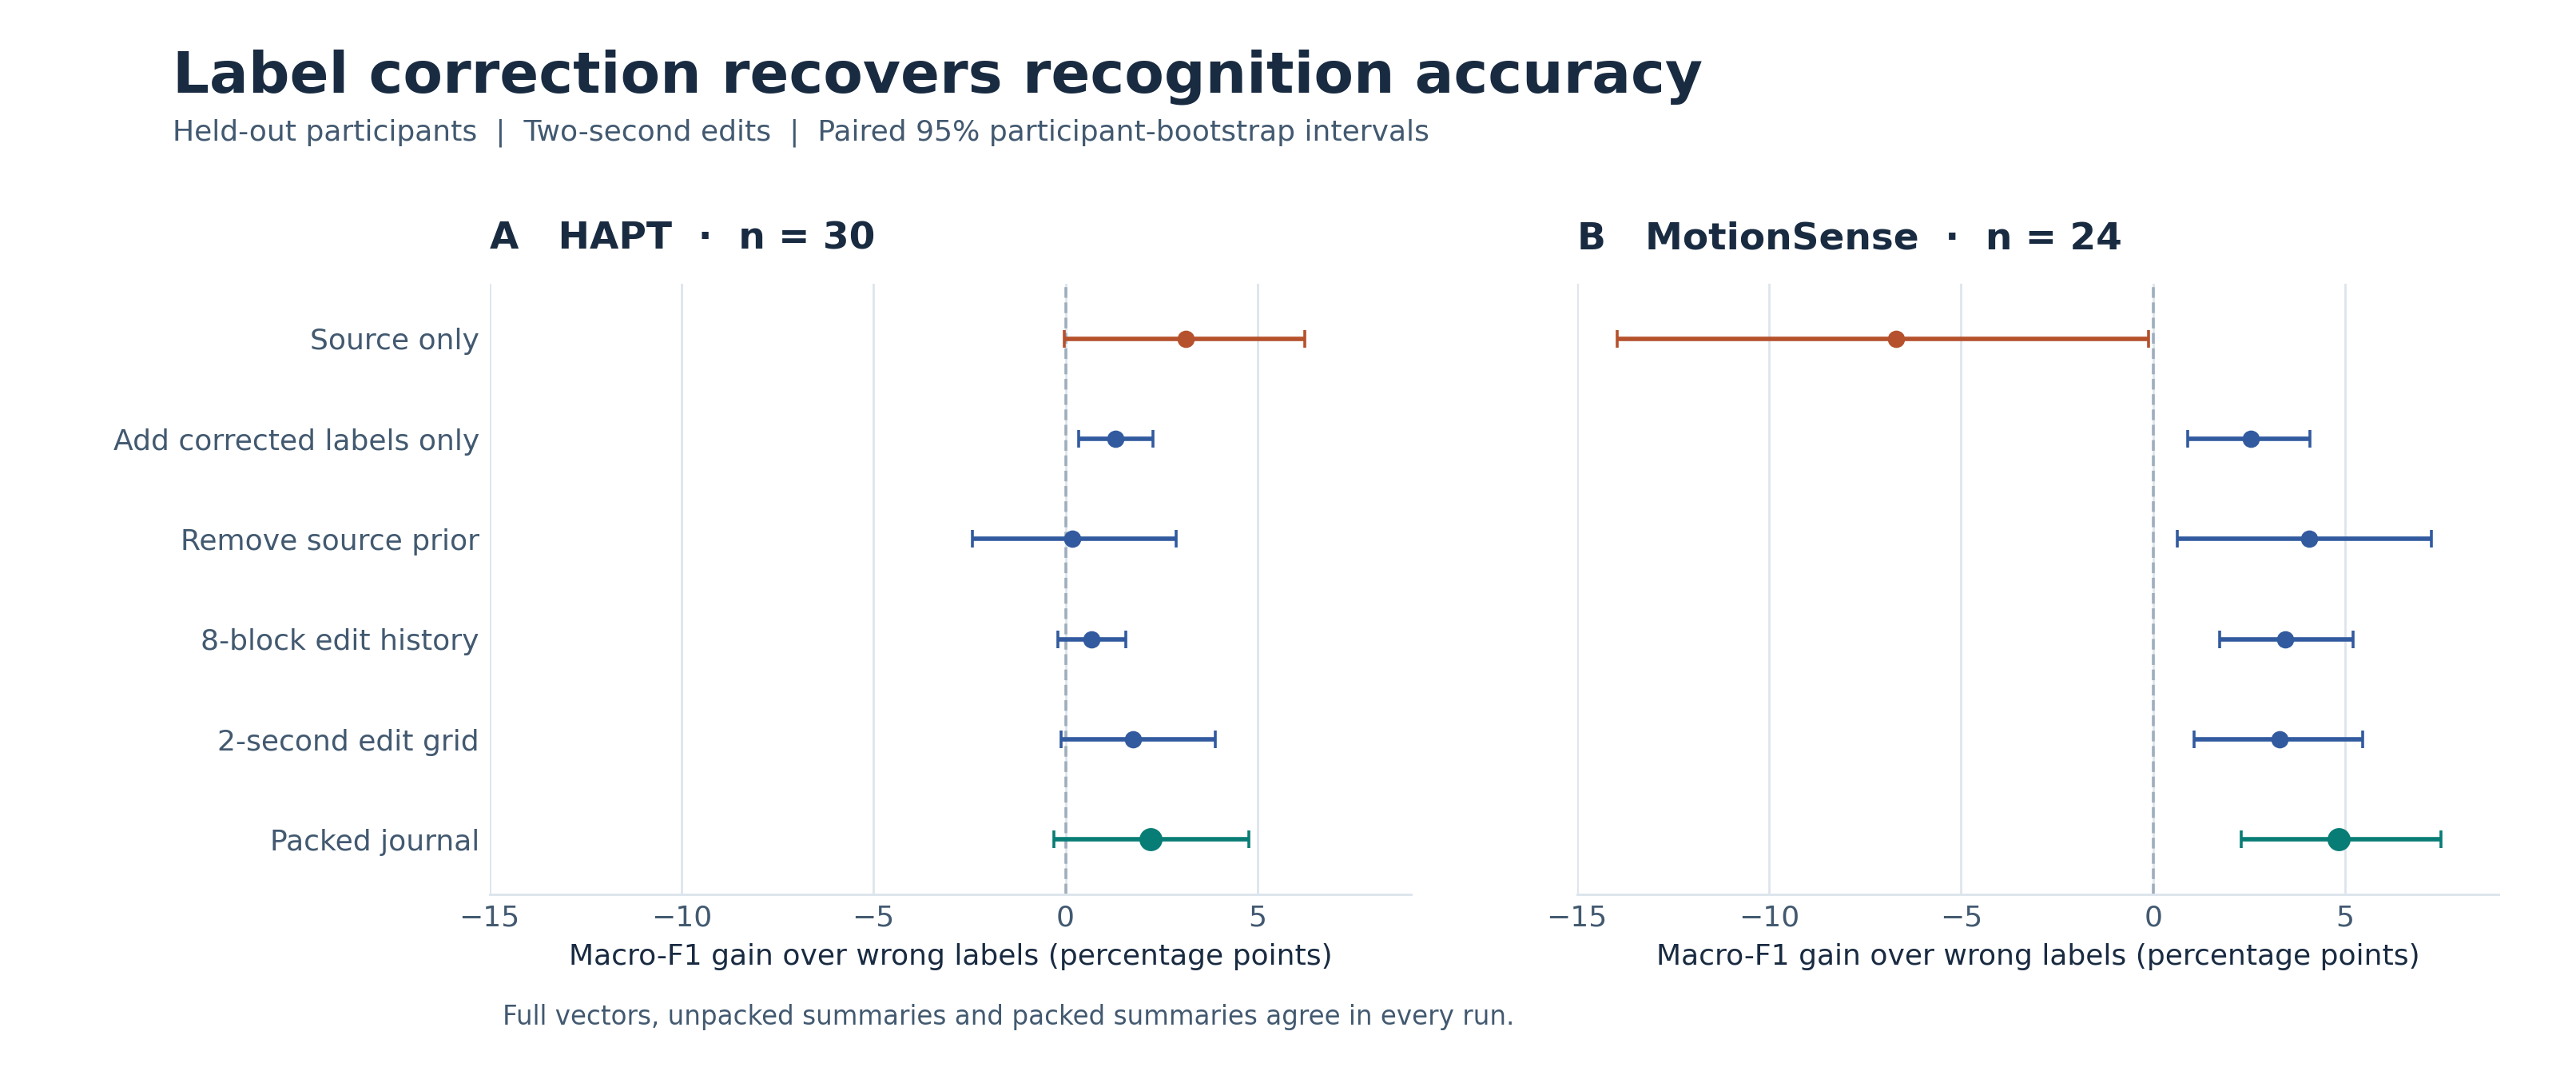

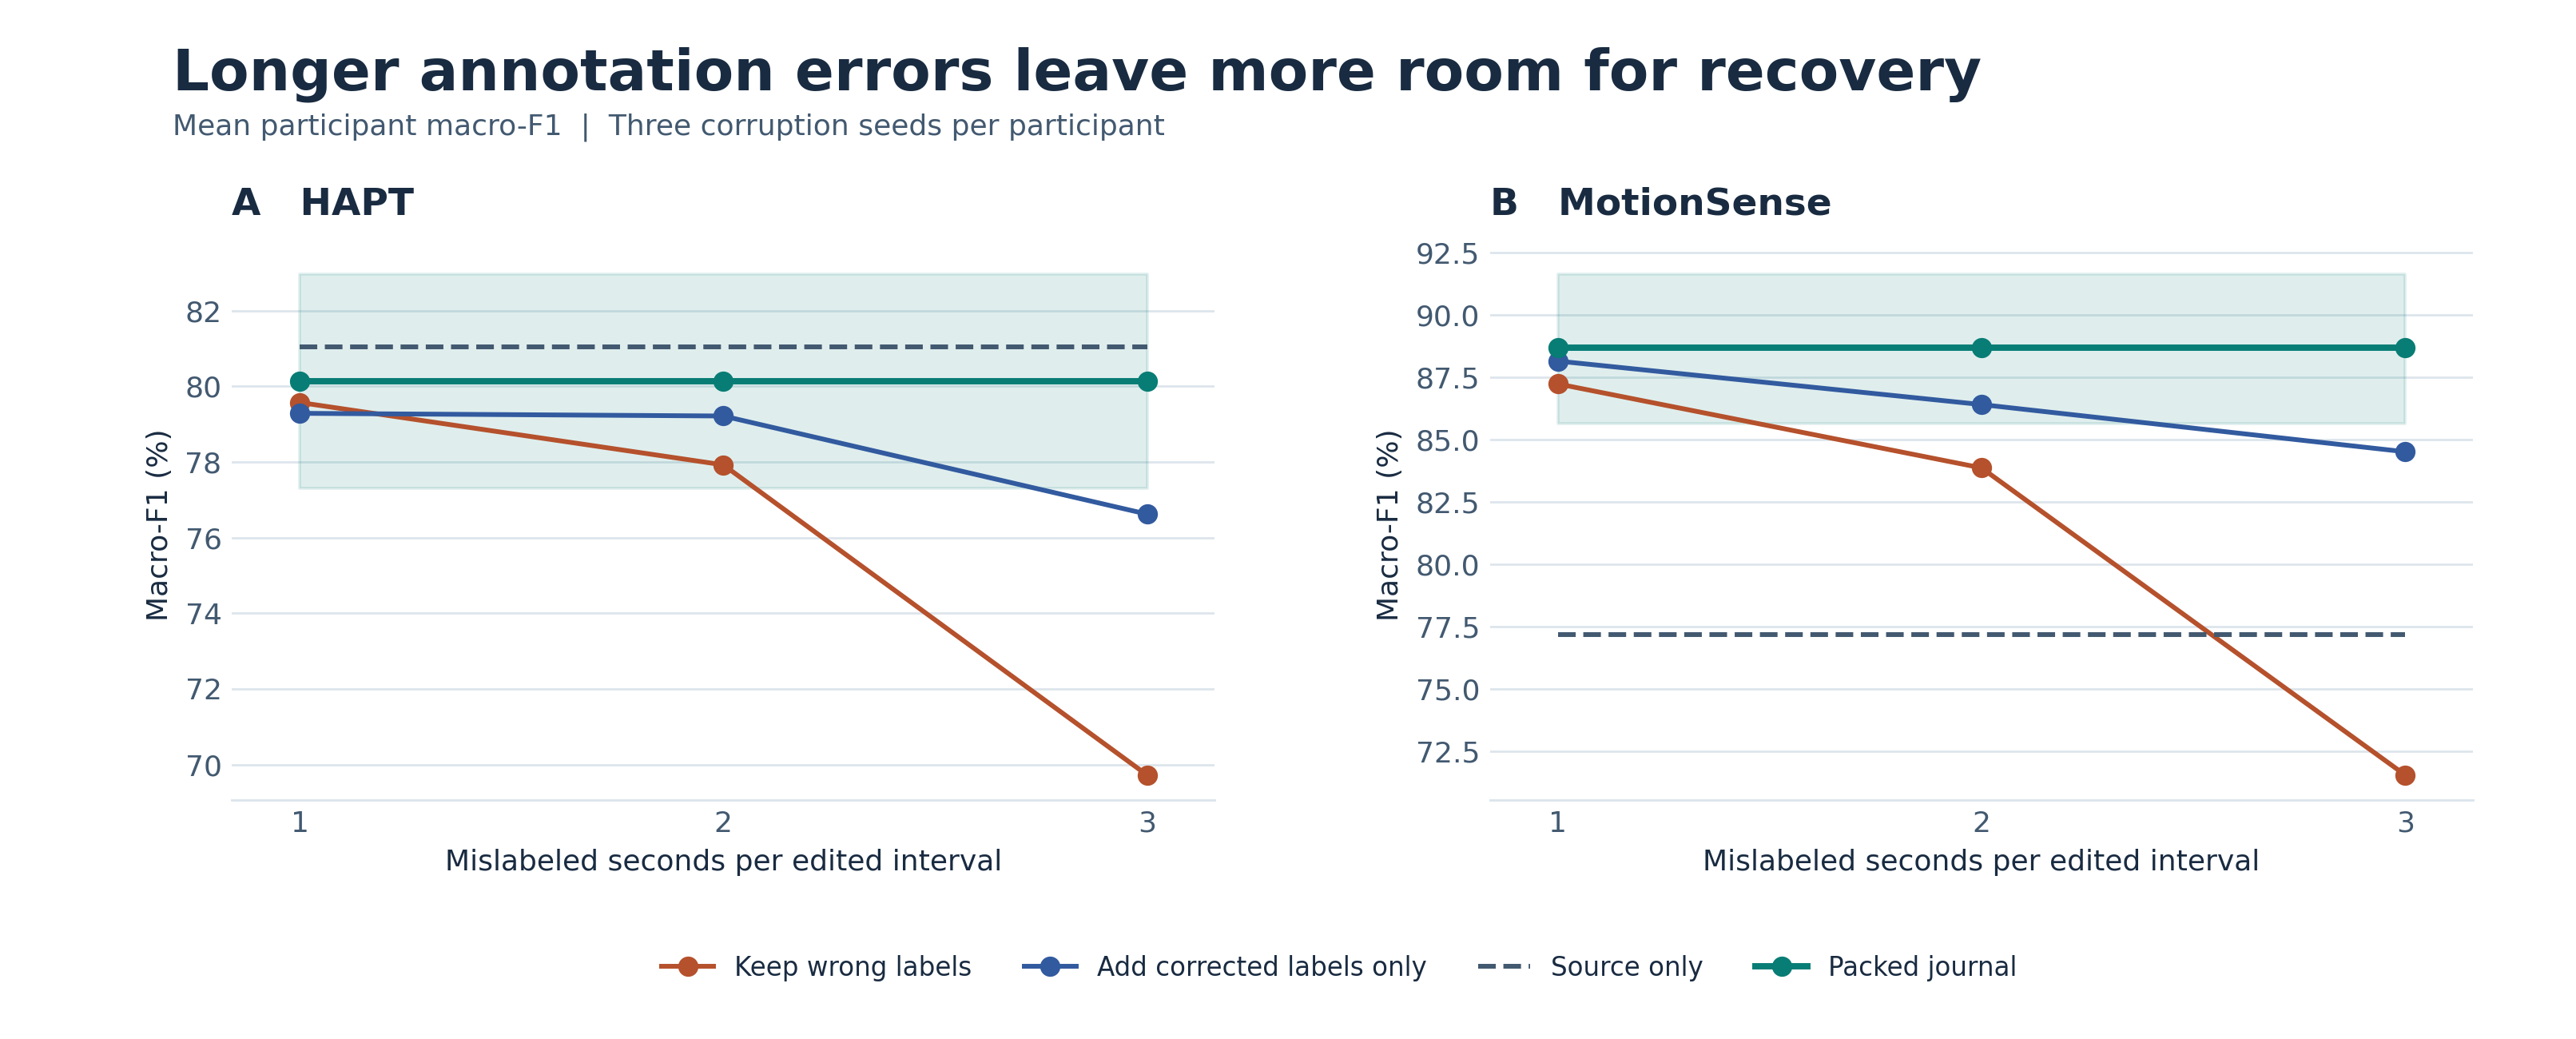

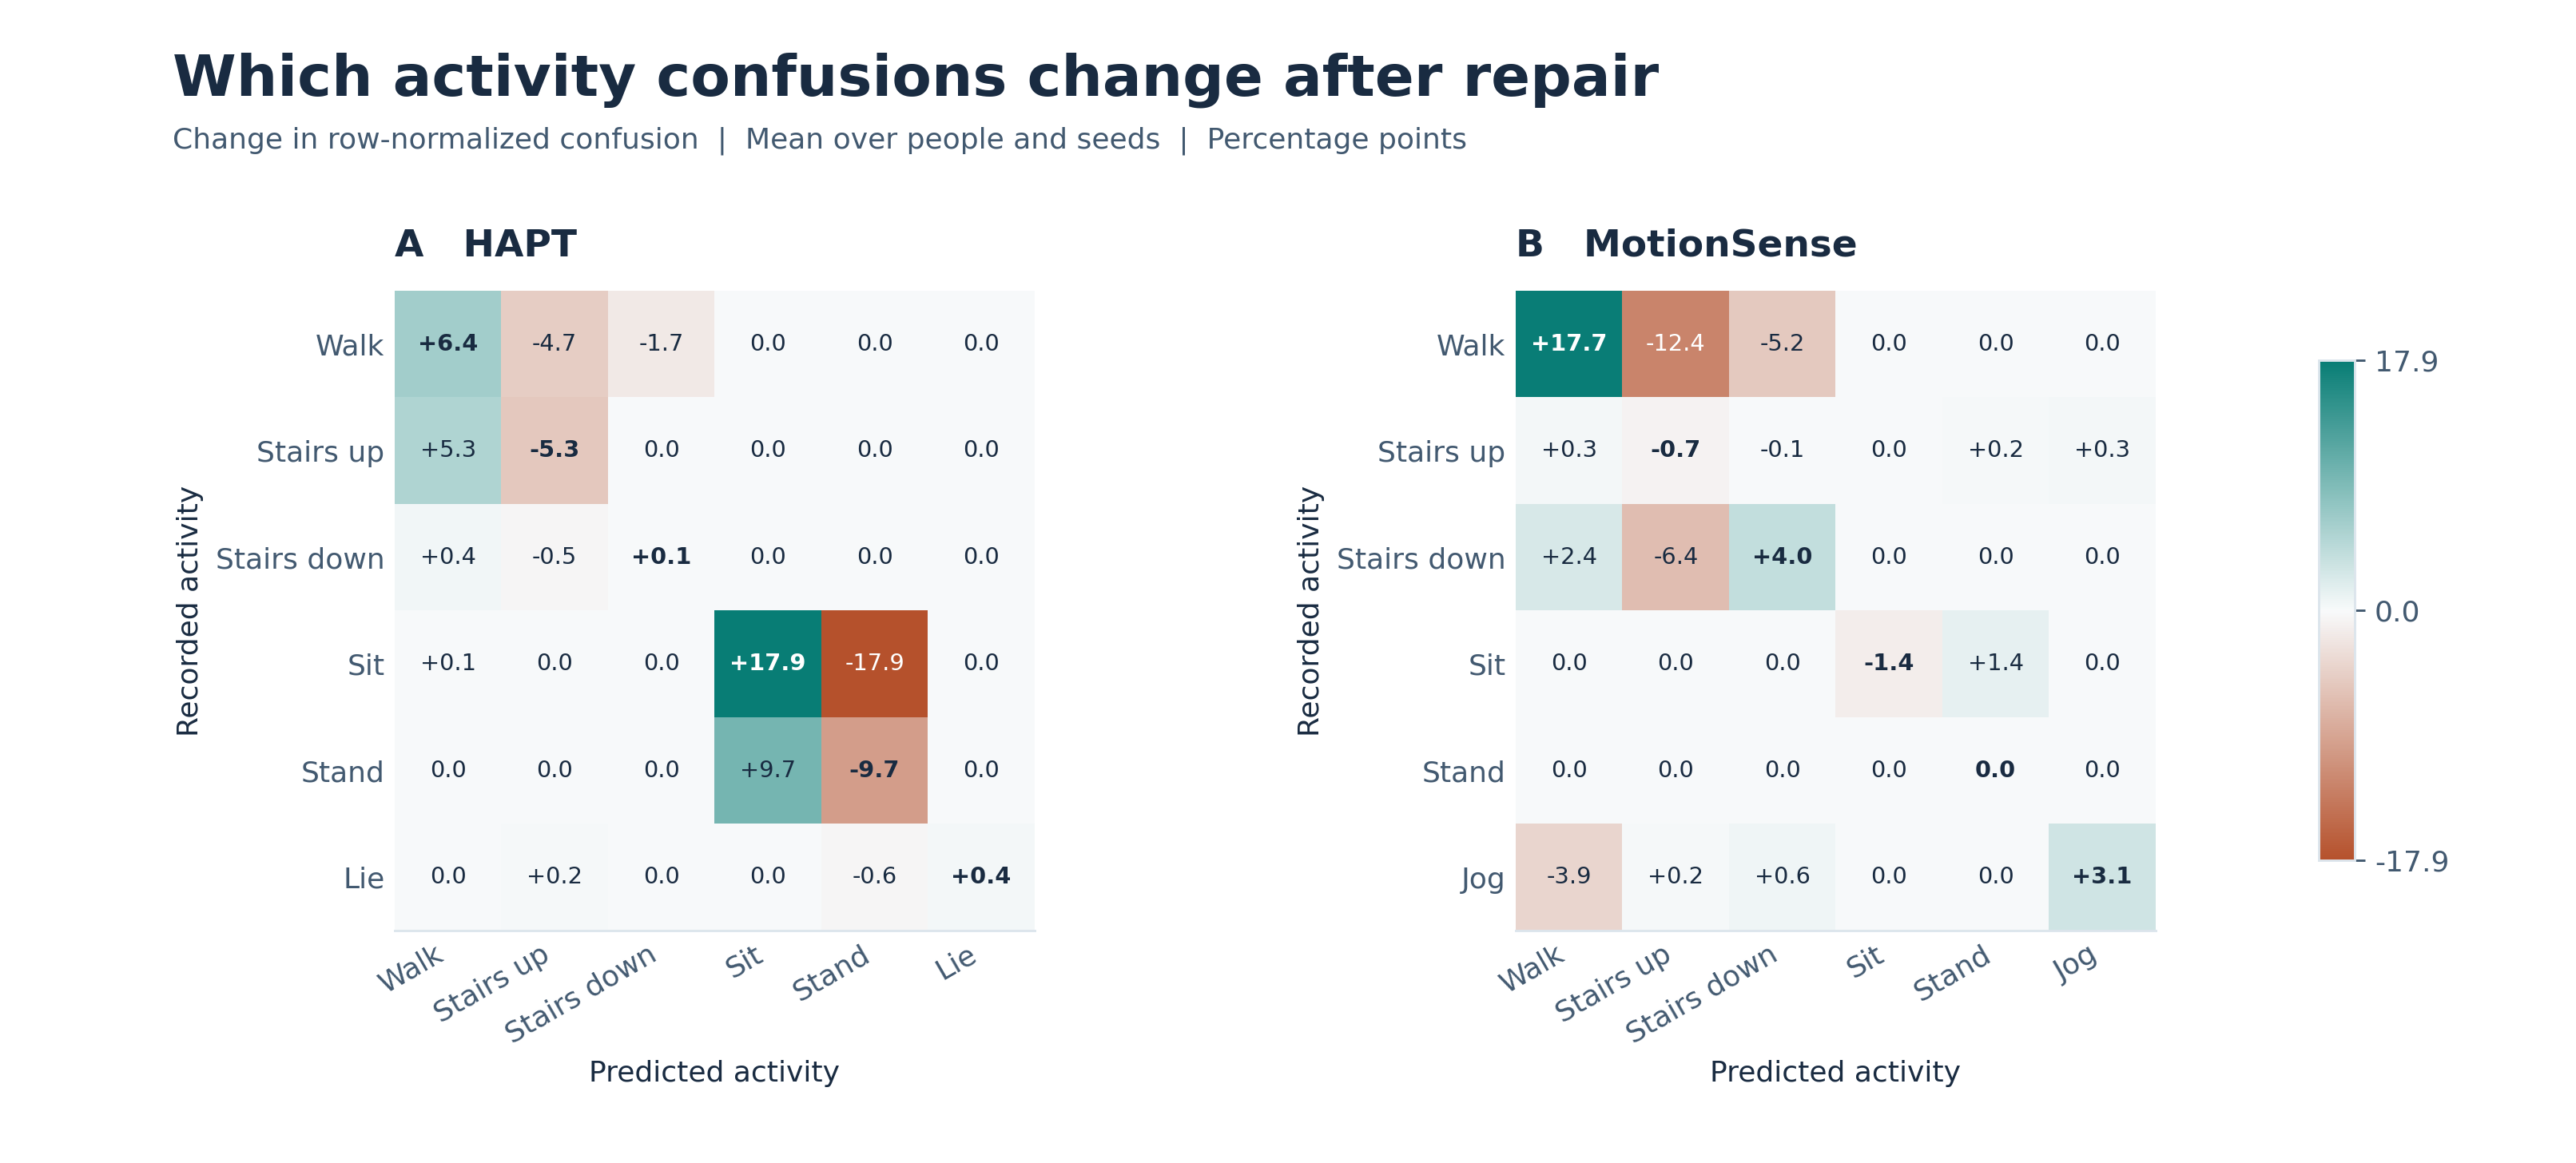

In [2]:
for filename in ("fig2_paired_effects.png", "fig3_error_duration.png", "fig5_confusion_change.png"):
    display(Image(filename=str(RESULTS / "figures" / filename), width=920))

## What each ablation removes
The full-vector implementations give exact references. The component tests exercise label subtraction, the source prior, history length, edit granularity, packing, retry IDs, CRC validation, and acknowledgement after checkpointing.

,Ablation,Change
0,Keep wrong labels,No edit applied
1,Add corrected labels only,Leave the old class contribution in place
2,Remove source prior,Use the corrected target-user means
3,8-block edit history,Reject edits touching earlier blocks
4,2-second edit grid,Accept only complete two-block pairs
5,Unpacked summaries,Store 32-bit sums with the same journal and pr...
6,Remove retry IDs,Treat a repeated request as a new edit
7,Remove CRC validation,Accept structurally valid corrupt payloads
8,Remove checkpoint receipt,Keep the high-water ID and discard the latest ...


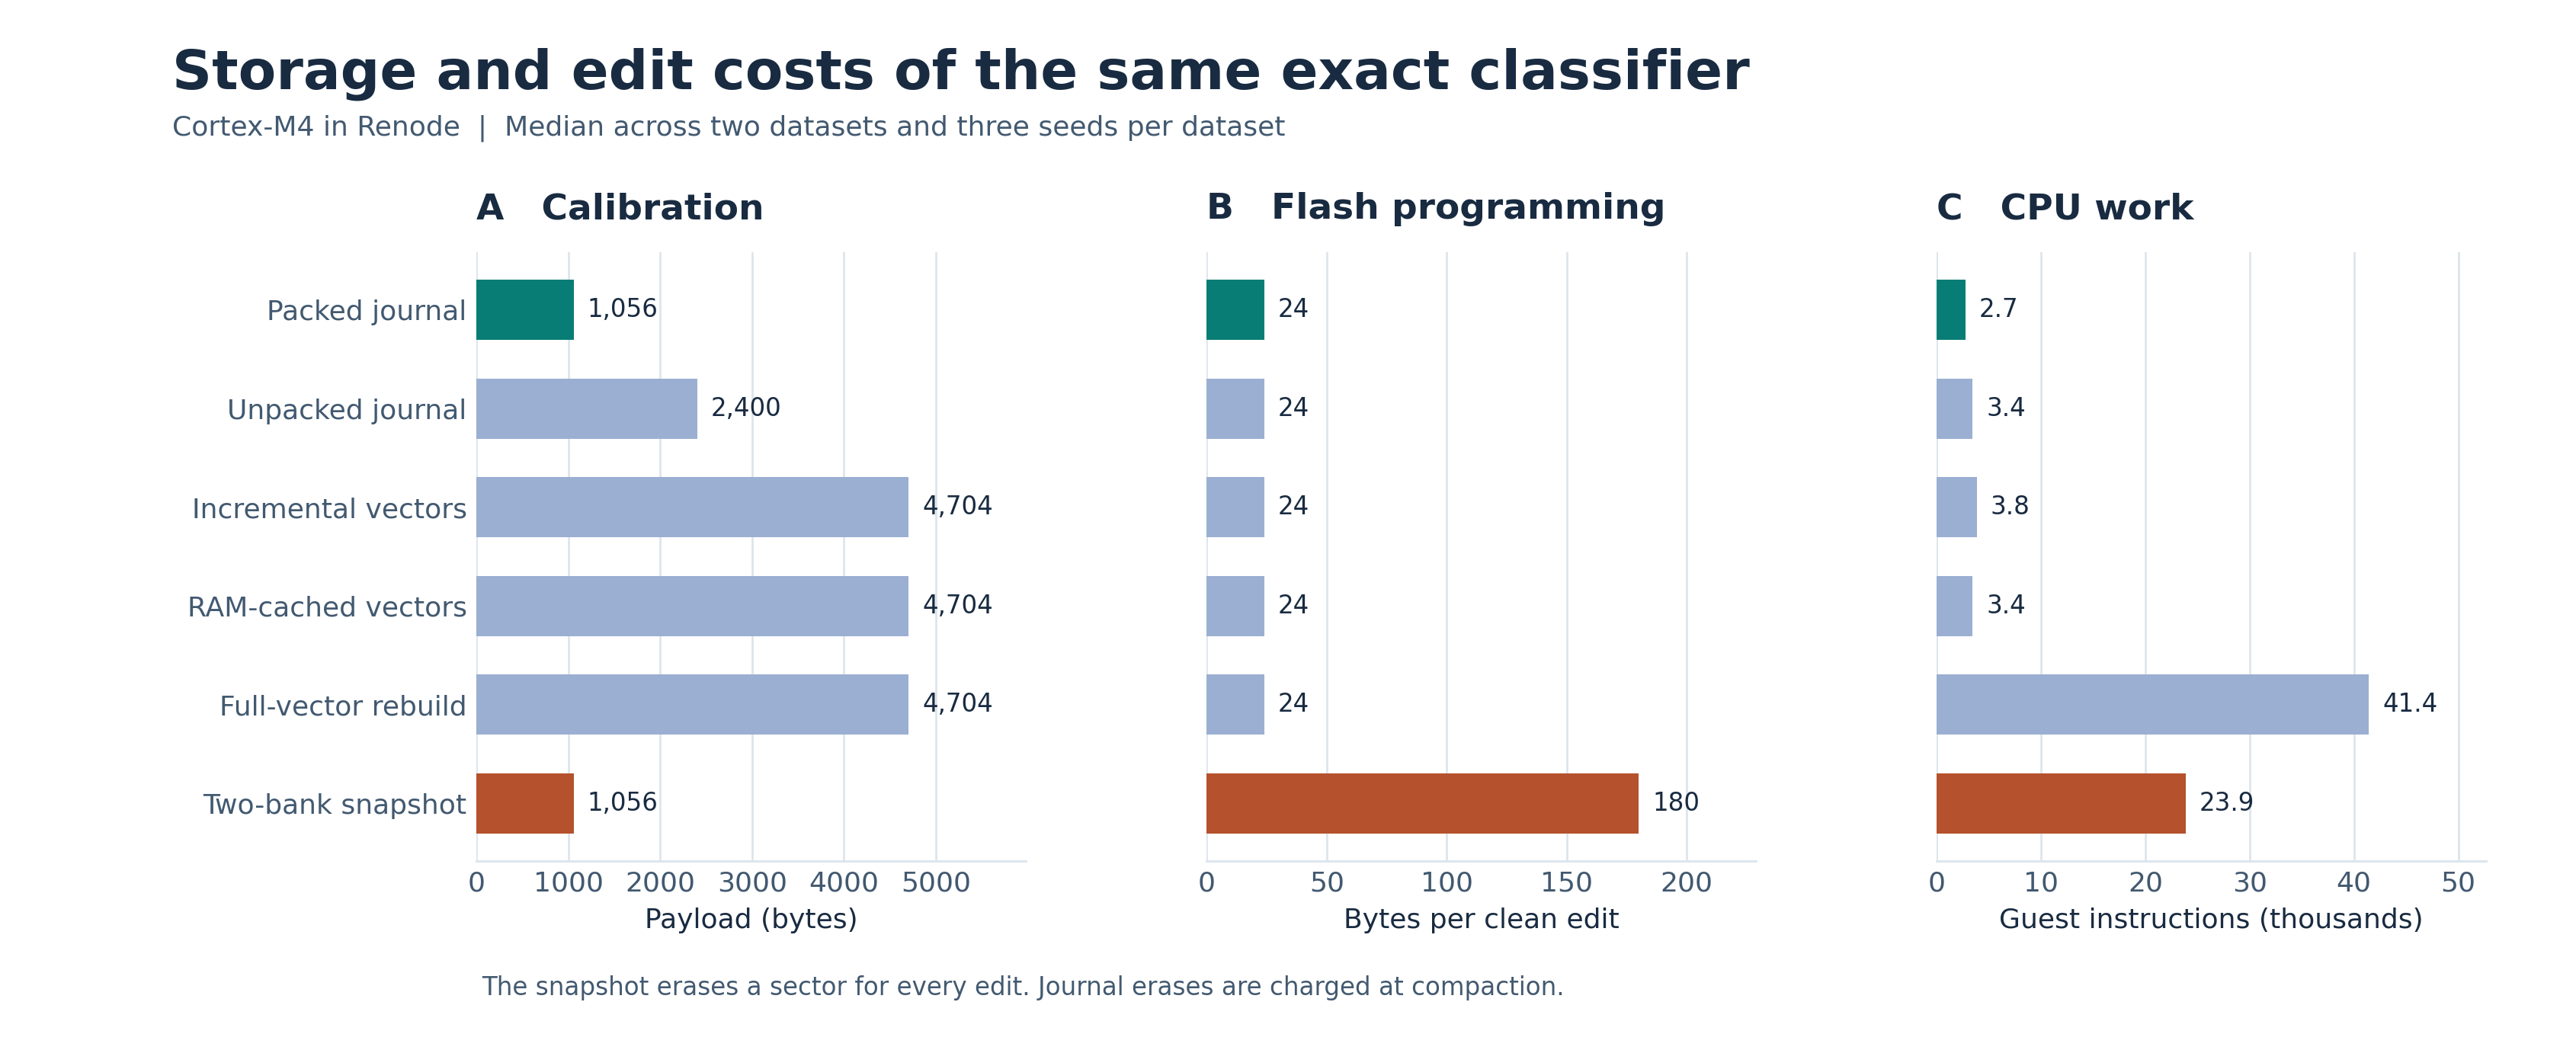

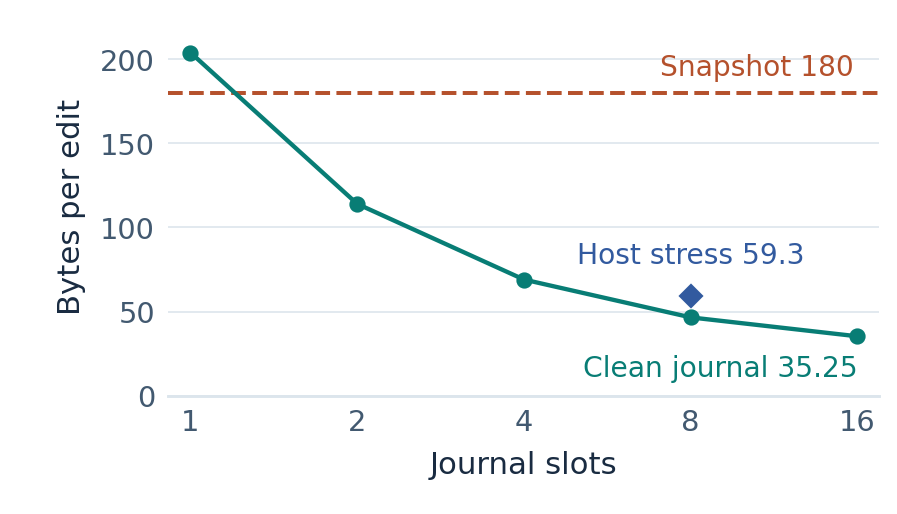

In [3]:
ablation = pd.DataFrame([
    ("Keep wrong labels", "No edit applied"),
    ("Add corrected labels only", "Leave the old class contribution in place"),
    ("Remove source prior", "Use the corrected target-user means"),
    ("8-block edit history", "Reject edits touching earlier blocks"),
    ("2-second edit grid", "Accept only complete two-block pairs"),
    ("Unpacked summaries", "Store 32-bit sums with the same journal and predictions"),
    ("Remove retry IDs", "Treat a repeated request as a new edit"),
    ("Remove CRC validation", "Accept structurally valid corrupt payloads"),
    ("Remove checkpoint receipt", "Keep the high-water ID and discard the latest payload"),
], columns=["Ablation", "Change"])
display(ablation)
display(Image(filename=str(RESULTS / "figures" / "fig4_firmware_cost.png"), width=920))
display(Image(filename=str(RESULTS / "figures" / "fig6_journal_write_cost.png"), width=470))

In [4]:
primary = paired[paired.edit_length_s == 2].pivot(index="dataset", columns="mode", values="macro_f1_pct")
delta = (primary.proposed - primary.source_only).rename("Journal minus source-only (pp)")
display(delta.to_frame().round(2))
display(pd.read_csv(RESULTS / "tables" / "paired_primary.csv").round(2))
print(f"Exact full-vector prediction agreement across {len(full)} participant × seed × duration cases.")

Exact full-vector prediction agreement across 486 participant × seed × duration cases.


,Journal minus source-only (pp)
dataset,
HAPT,-0.91
MotionSense,11.51


,dataset,reference,participants,delta_pp,ci_low,ci_high
0,HAPT,no_correction,30,2.22,-0.31,4.78
1,HAPT,source_only,30,-0.91,-3.62,1.77
2,HAPT,add_only,30,0.93,-1.46,3.31
3,MotionSense,no_correction,24,4.83,2.30,7.50
4,MotionSense,source_only,24,11.51,5.01,18.99
5,MotionSense,add_only,24,2.29,0.61,4.17


Use the repository's SVG or PNG exports for figures and the CSV or LaTeX table for exact values. Recognition quality reflects the simulated label-error workload. Simulator instruction counts and flash operations characterize the implementation under the stated model.